# 02 · Experimentación: búsqueda de hiperparámetros

**Proyecto del curso de Deep Learning** · Juan Sebastian Higuita Riascos · Universidad Nacional de Colombia

El resultado principal del proyecto usa hiperparámetros **fijados de antemano** (`config/protocolo.json`). Este notebook responde dos preguntas que eso deja abiertas:

1. ¿Cuánto mejora cada modelo si se ajustan sus hiperparámetros?
2. ¿Cambian las conclusiones sobre las arquitecturas cuando cada una tiene su propia búsqueda?

| Sección | Contenido |
|---|---|
| 1 | Las reglas de la búsqueda (para no hacer trampa) |
| 2 | Un experimento en vivo: esta celda **entrena** |
| 3 | Resultados por arquitectura: qué configuración ganó y qué hiperparámetros importan |
| 4 | ¿Mejoró? Protocolo fijo frente a búsqueda, en la prueba |
| 5 | ¿Cambia la comparación entre arquitecturas? |
| 6 | Modelos guardados: cargar uno y volver a predecir |
| 7 | Conclusiones y límites |

In [1]:
import sys
import warnings
from pathlib import Path

from IPython.display import display

warnings.filterwarnings("ignore")

# Ubicar la carpeta del repositorio y hacer visible su código (src/)
RAIZ = next(
    carpeta
    for carpeta in [Path.cwd(), *Path.cwd().parents]
    if (carpeta / "config" / "protocolo.json").is_file()
)
sys.path.insert(0, str(RAIZ / "src"))

from informe import datos, graficos
from informe.interactivo import Lista, controles

graficos.aplicar_estilo()
res = datos.cargar(RAIZ)
print(f"{len(res.ids)} ejemplos de {res.tabla.kepid.nunique()} estrellas, listos en `res`.")

import pandas as pd

from comun.protocolo import cargar_protocolo
from informe import experimentacion
from temporal import busqueda_ramas

protocolo = cargar_protocolo(RAIZ / "config" / "protocolo.json")
ejemplos = pd.read_csv(RAIZ / "compartido" / "ejemplos.csv")
ARQUITECTURAS = experimentacion.arquitecturas_disponibles(res)
print("Búsquedas terminadas:", ", ".join(experimentacion.NOMBRE[a] for a in ARQUITECTURAS))

490 ejemplos de 245 estrellas, listos en `res`.


Búsquedas terminadas: Rama 1 · CNN tipo AstroNet, Rama 2 · promedio, Rama 2 · GRU, Rama 2 · atención, Rama 4 · escalares, Cabeza de fusión


## 1 · Las reglas de la búsqueda

Buscar hiperparámetros es la forma más fácil de engañarse: si se prueban muchas configuraciones y se reporta la mejor **en la prueba**, el número sale inflado. Estas son las reglas (spec 009):

1. **El espacio se declara antes de entrenar** y no se toca después. Está en `src/temporal/busqueda_ramas.py`.
2. **Búsqueda aleatoria** con semilla fija: 8 configuraciones por arquitectura, la del protocolo (`cfg00`) y 7 sorteadas. Con 5 o 6 hiperparámetros, sortear cubre más valores distintos de cada uno que una rejilla del mismo tamaño (Bergstra y Bengio, 2012).
3. **Mismo presupuesto para todas las arquitecturas**: si una recibiera más intentos, ganaría por eso.
4. **Selección anidada.** Hay 5 modelos por configuración, uno por partición. El modelo de la partición *k* elige su configuración con su **validación interna** (la partición *k* + 1). La partición de prueba *k* nunca interviene.
5. **Se reportan las dos versiones**, protocolo fijo y con búsqueda, con su diferencia pareada e intervalo del 95 %.

El tamaño de los vectores (32, 32, 16) no se busca: lo fija el contrato de integración entre ramas.

**Prueba esto.** Cambia la arquitectura para ver su espacio de búsqueda.

In [2]:
OPCIONES = [(experimentacion.NOMBRE[a], a) for a in ARQUITECTURAS]

controles(
    lambda arquitectura: experimentacion.espacio_de_busqueda(arquitectura),
    arquitectura=Lista("Arquitectura:", OPCIONES),
)

,hiperparámetro,valores posibles,protocolo
0,tasa de aprendizaje,continuo entre 0.0003 y 0.003 (escala logarítm...,0.001
1,decaimiento de pesos,"0.0, 1e-05, 0.0001, 0.001",0.0001
2,tamaño de lote,"32, 64",32
3,dropout,"0.1, 0.3, 0.5",0.3
4,ancho (multiplica los filtros),"0.5, 1.0",1.0
5,pooling,"max, promedio",max


(Vista fija con Arquitectura: m1_astronet. Ejecuta el notebook para usar los controles.)


## 2 · Un experimento en vivo

La celda siguiente **entrena de verdad**: lanza una búsqueda pequeña de la rama 4 (la más rápida) en una carpeta aparte, para no tocar los resultados del proyecto. Cada configuración entrena 5 modelos (uno por partición) con parada temprana.

- Lo ya entrenado se guarda: la segunda vez que la ejecutes termina en segundos.
- Sube `N_CONFIGURACIONES` y se entrenan solo las que falten.
- Cambia `ARQUITECTURA` por `"m2_atencion"` para ver la misma búsqueda sobre una red más grande (tarda varios minutos por configuración).

In [3]:
ARQUITECTURA = "m4_escalares"
N_CONFIGURACIONES = 3
CARPETA_DE_PRUEBA = RAIZ / "resultados" / "dl" / "busqueda_demo"  # no se versiona

# 1. Qué configuraciones se van a entrenar (la primera es siempre la del protocolo)
for indice, configuracion in enumerate(busqueda_ramas.configuraciones_de(ARQUITECTURA, N_CONFIGURACIONES)):
    print(f"cfg{indice:02d}", configuracion)

# 2. Entrenar las que falten y resumir con selección anidada
resumen = busqueda_ramas.ejecutar(
    ARQUITECTURA, res.dataset, ejemplos, protocolo, CARPETA_DE_PRUEBA, n=N_CONFIGURACIONES
)

# 3. Qué eligió cada partición y qué pasó en la prueba
print("\nConfiguración elegida por cada partición:", resumen["elegida_por_particion"])
print("NLL de validación · protocolo:", resumen["nll_validacion"]["fijo"],
      "· con búsqueda:", resumen["nll_validacion"]["con_busqueda"])
print("AUC en prueba · protocolo:", resumen["auc_prueba"]["fijo"]["estimacion"],
      "· con búsqueda:", resumen["auc_prueba"]["con_busqueda"]["estimacion"])

cfg00 {'tasa_aprendizaje': 0.001, 'weight_decay': 0.0001, 'lote': 32, 'dropout': 0.2, 'oculta': 32}
cfg01 {'tasa_aprendizaje': 0.00164, 'weight_decay': 1e-05, 'lote': 16, 'dropout': 0.2, 'oculta': 64}
cfg02 {'tasa_aprendizaje': 0.00117, 'weight_decay': 0.0001, 'lote': 32, 'dropout': 0.2, 'oculta': 32}



Configuración elegida por cada partición: ['cfg01', 'cfg01', 'cfg01', 'cfg01', 'cfg01']
NLL de validación · protocolo: 0.1979 · con búsqueda: 0.1746
AUC en prueba · protocolo: 0.9573 · con búsqueda: 0.9516


**Cómo leerlo.** La NLL de validación "con búsqueda" siempre es menor o igual que la del protocolo: se eligió mirándola, así que es **optimista por construcción**. Lo que cuenta es el AUC en prueba, que no participó en la elección. Con 3 configuraciones esto es solo una demostración del mecanismo; los resultados del proyecto están en las secciones siguientes.

## 3 · Resultados por arquitectura

**Cómo leer la figura.** Cada columna es una configuración, ordenadas de mejor a peor. Los 5 puntos son los 5 modelos (uno por partición) y el rombo su media. En naranja, el protocolo. Con borde negro, los modelos que ganó cada partición en la selección anidada.

**Qué mirar.** Si los puntos de una misma configuración están muy separados, la partición pesa más que el hiperparámetro: la búsqueda tiene poco de dónde agarrarse.

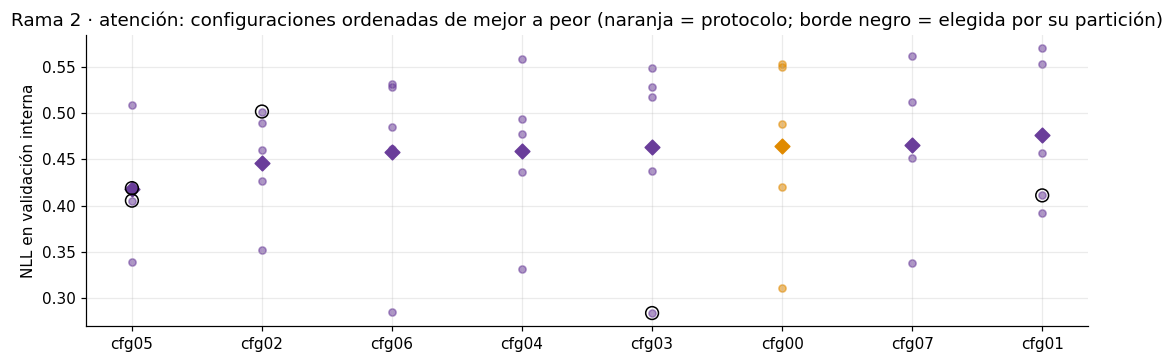

,configuracion,tasa_aprendizaje,weight_decay,lote,dropout,ancho,cabezas,parametros,epocas_medias,nll_val_media
0,cfg05,0.000313,0.0000,16,0.3,2.0,4,22436,41.6,0.4179
1,cfg02,0.000524,0.0010,16,0.5,2.0,2,22436,46.6,0.4461
2,cfg06,0.002620,0.0010,16,0.3,1.0,2,13604,40.4,0.4584
3,cfg04,0.000406,0.0010,64,0.3,1.0,4,13604,62.8,0.4596
4,cfg03,0.001210,0.0001,32,0.3,1.0,4,13604,34.2,0.4636
5,cfg00,0.001000,0.0001,32,0.3,1.0,2,13604,33.4,0.4647
6,cfg07,0.001010,0.0000,32,0.1,1.0,2,13604,23.6,0.4661
7,cfg01,0.000366,0.0001,16,0.1,0.5,2,11108,41.8,0.4771


(Vista fija con Arquitectura: m2_atencion. Ejecuta el notebook para usar los controles.)


In [4]:
controles(
    lambda arquitectura: experimentacion.configuraciones(res, arquitectura),
    arquitectura=Lista("Arquitectura:", OPCIONES, inicial="m2_atencion"),
)

### ¿Qué hiperparámetros importan?

**Prueba esto.** Elige un hiperparámetro y mira si la NLL de validación sigue alguna tendencia. Con 8 puntos y todo cambiando a la vez, solo se pueden ver tendencias fuertes.

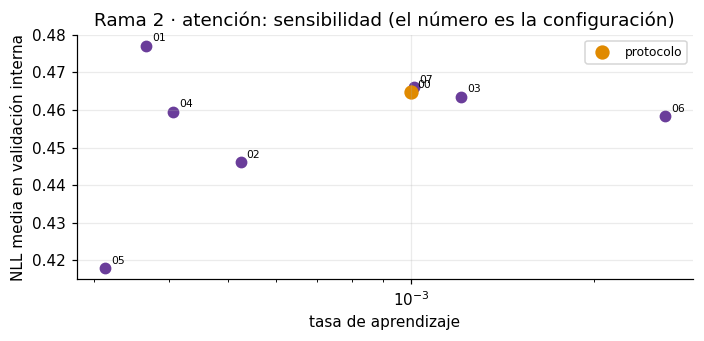

(Vista fija con Arquitectura: m2_atencion, Hiperparámetro: tasa_aprendizaje. Ejecuta el notebook para usar los controles.)


In [5]:
HIPERPARAMETROS = [
    (nombre, clave) for clave, nombre in experimentacion.NOMBRE_DE_HIPERPARAMETRO.items()
]

controles(
    lambda arquitectura, hiperparametro: experimentacion.sensibilidad(res, arquitectura, hiperparametro),
    arquitectura=Lista("Arquitectura:", OPCIONES, inicial="m2_atencion"),
    hiperparametro=Lista("Hiperparámetro:", HIPERPARAMETROS),
)

### ¿Cómo entrenó una configuración frente al protocolo?

Azul: pérdida de entrenamiento. Rojo: validación interna. La línea vertical es la época que eligió la parada temprana.

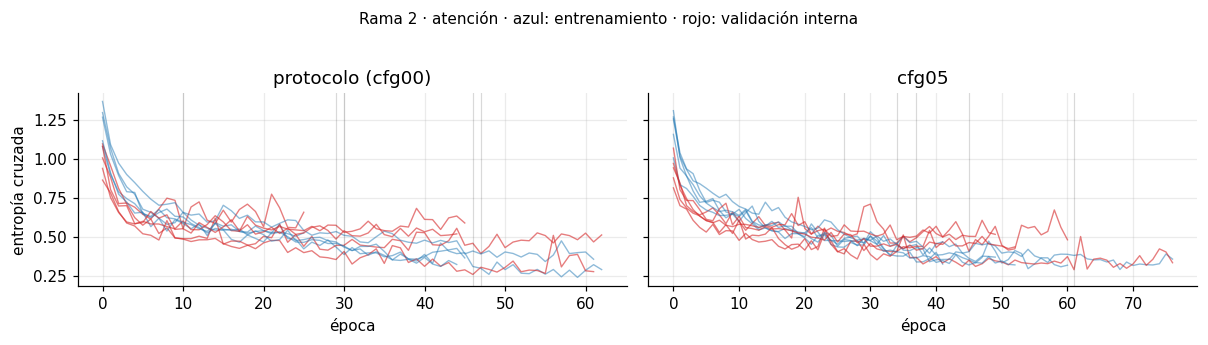

(Vista fija con Arquitectura: m2_atencion, Configuración: cfg05. Ejecuta el notebook para usar los controles.)


In [6]:
CONFIGURACIONES = [f"cfg{i:02d}" for i in range(1, busqueda_ramas.N_CONFIGURACIONES)]

controles(
    lambda arquitectura, configuracion: experimentacion.curvas(res, arquitectura, configuracion),
    arquitectura=Lista("Arquitectura:", OPCIONES[:-1], inicial="m2_atencion"),
    configuracion=Lista("Configuración:", CONFIGURACIONES, inicial="cfg05"),
)

## 4 · ¿Mejoró? Protocolo fijo frente a búsqueda

Ahora sí se mira la **prueba**. Para cada modelo: el AUC del protocolo, el AUC con la configuración que eligió cada partición, y la diferencia pareada (mismas estrellas remuestreadas) con su intervalo del 95 %.

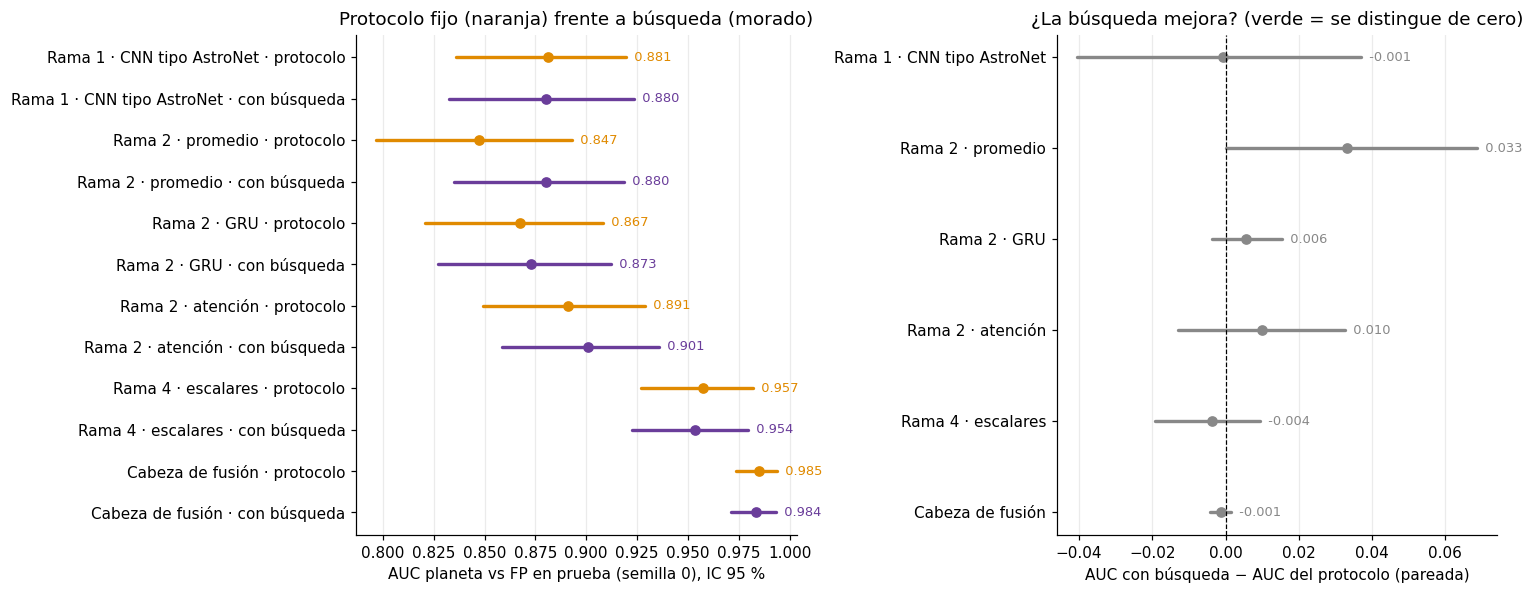

,modelo,AUC protocolo,AUC con búsqueda,diferencia,IC inf,IC sup,se distingue de 0
0,Rama 1 · CNN tipo AstroNet,0.8810,0.8803,-0.0007,-0.0406,0.0370,False
1,Rama 2 · promedio,0.8472,0.8803,0.0332,-0.0000,0.0687,False
2,Rama 2 · GRU,0.8674,0.8730,0.0057,-0.0038,0.0154,False
3,Rama 2 · atención,0.8912,0.9011,0.0099,-0.0129,0.0325,False
4,Rama 4 · escalares,0.9573,0.9536,-0.0037,-0.0192,0.0093,False
5,Cabeza de fusión,0.9849,0.9837,-0.0012,-0.0043,0.0016,False


In [7]:
tabla_mejora = experimentacion.fijo_contra_busqueda(res)
display(tabla_mejora)

**Lectura.**

- **En ningún modelo la mejora se distingue de cero.** El caso más favorable es la rama 2 con promedio, cuyo intervalo queda rozando el 0.
- En la rama 4, la rama 1 y la cabeza de fusión, la búsqueda quedó igual o apenas por debajo del protocolo: los valores fijados de antemano ya estaban en una zona razonable.
- **Cuidado con el caso del promedio.** Su punto de partida (semilla 0 del protocolo) fue la más baja de sus tres semillas, así que parte de la subida puede ser simple variación entre entrenamientos y no efecto de los hiperparámetros. Con una sola semilla no se pueden separar las dos cosas.
- La validación mejoró en todos (se eligió mirándola), pero esa mejora **no se trasladó** a la prueba de forma medible. Es la señal clásica de que, con ~100 ejemplos de validación por partición, la selección persigue ruido.

## 5 · ¿Cambia la comparación entre arquitecturas?

La pregunta 1 del proyecto compara arquitecturas con un protocolo común. Aquí se repite la comparación cuando **cada una tuvo su propia búsqueda**.

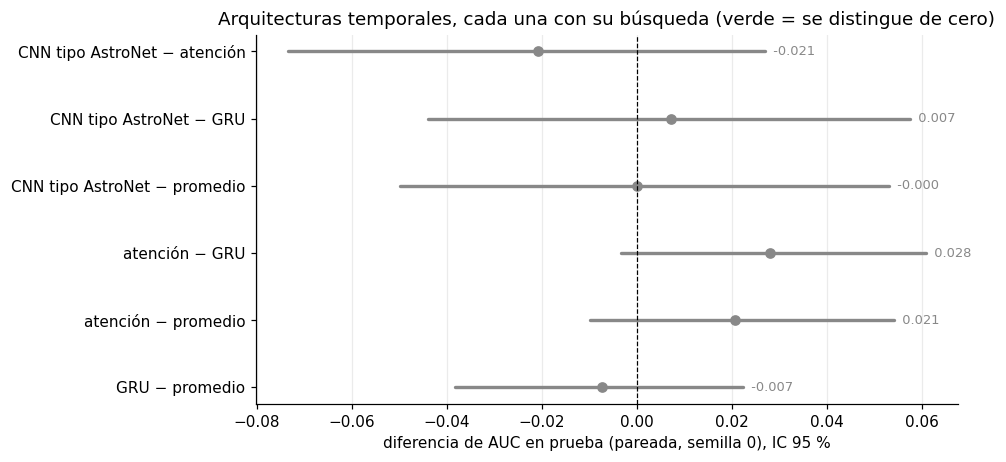

,par,estimacion,ic_inf,ic_sup,distinguible
0,CNN tipo AstroNet − atención,-0.0208,-0.0734,0.0269,False
1,CNN tipo AstroNet − GRU,0.0072,-0.0439,0.0575,False
2,CNN tipo AstroNet − promedio,-0.0001,-0.0499,0.0531,False
3,atención − GRU,0.0280,-0.0034,0.0607,False
4,atención − promedio,0.0207,-0.0099,0.0541,False
5,GRU − promedio,-0.0073,-0.0383,0.0222,False


In [8]:
tabla_pares = experimentacion.pares_con_busqueda(res)
display(tabla_pares)

**Lectura.** Con búsqueda, **ninguna diferencia entre arquitecturas temporales se distingue de cero**. La atención sigue teniendo el AUC más alto, pero su ventaja sobre el promedio, la GRU y la CNN de curva plegada cabe dentro del intervalo.

Esto **refuerza** la conclusión del protocolo fijo ("la atención no supera al promedio de forma demostrable") y matiza la única diferencia que allí salía distinguible (atención sobre GRU): con una semilla y búsqueda, tampoco se distingue.

## 6 · Modelos guardados

El modelo que eligió cada partición quedó guardado completo en `modelos/mejores/<arquitectura>/`, con la estandarización de sus entradas y un manifiesto (hiperparámetros y huella SHA-256). Al guardarlo se comprobó que reproduce las predicciones de la búsqueda.

In [9]:
guardados = experimentacion.modelos_guardados(res)
display(guardados[["modelo", "partición", "archivo", "configuración"]])

,modelo,partición,archivo,configuración
0,Rama 1 · CNN tipo AstroNet,0,modelos/mejores/m1_astronet/particion_0.keras,cfg03
1,Rama 1 · CNN tipo AstroNet,1,modelos/mejores/m1_astronet/particion_1.keras,cfg07
2,Rama 1 · CNN tipo AstroNet,2,modelos/mejores/m1_astronet/particion_2.keras,cfg00
3,Rama 1 · CNN tipo AstroNet,3,modelos/mejores/m1_astronet/particion_3.keras,cfg07
4,Rama 1 · CNN tipo AstroNet,4,modelos/mejores/m1_astronet/particion_4.keras,cfg01
5,Rama 2 · promedio,0,modelos/mejores/m2_promedio/particion_0.keras,cfg02
6,Rama 2 · promedio,1,modelos/mejores/m2_promedio/particion_1.keras,cfg07
7,Rama 2 · promedio,2,modelos/mejores/m2_promedio/particion_2.keras,cfg03
8,Rama 2 · promedio,3,modelos/mejores/m2_promedio/particion_3.keras,cfg03
9,Rama 2 · promedio,4,modelos/mejores/m2_promedio/particion_4.keras,cfg04


### Cargar un modelo y volver a predecir

`temporal/despliegue.py` carga el modelo, verifica su huella y aplica la misma estandarización. Se predice la partición que ese modelo **nunca vio** y se compara con lo reportado: la diferencia debe ser 0.

In [10]:
controles(
    lambda arquitectura, particion: experimentacion.probar_modelo_guardado(res, arquitectura, particion),
    arquitectura=Lista("Arquitectura:", OPCIONES[:-1], inicial="m2_atencion"),
    particion=Lista("Partición:", [0, 1, 2, 3, 4]),
)

Rama 2 · atención, partición 0: 96 ejemplos que el modelo nunca vio. Diferencia máxima con las probabilidades reportadas: 0.0e+00
Hiperparámetros del modelo guardado: {'tasa_aprendizaje': 0.000313, 'weight_decay': 0.0, 'lote': 16, 'dropout': 0.3, 'ancho': 2.0, 'cabezas': 4}


,id_ejemplo,clase real,P(planeta) del modelo cargado,P(planeta) reportada
0,K06261.01|transito,Falso positivo,0.702,0.702
1,K01004.01|sin_senal,Sin señal,0.004,0.004
2,K01004.01|transito,Falso positivo,0.001,0.001
3,K01976.01|sin_senal,Sin señal,0.001,0.001
4,K01976.01|transito,Planeta,0.961,0.961
5,K02413.01|sin_senal,Sin señal,0.002,0.002
6,K02413.01|transito,Planeta,0.399,0.399
7,K01830.01|sin_senal,Sin señal,0.009,0.009


(Vista fija con Arquitectura: m2_atencion, Partición: 0. Ejecuta el notebook para usar los controles.)


## 7 · Conclusiones y límites

**Qué se concluye**

1. Con el presupuesto usado (8 configuraciones, una semilla), ajustar hiperparámetros **no mejora ningún modelo de forma distinguible** en la prueba.
2. La comparación entre arquitecturas **no depende** de haber fijado el protocolo: con búsqueda, las arquitecturas temporales siguen sin distinguirse.
3. Por eso **el resultado principal sigue siendo el del protocolo fijo**, y esta búsqueda se reporta como análisis de sensibilidad (decisión D-3 de la spec 009). No se rehízo la fusión con los modelos buscados.

**Qué no se puede concluir**

- Que estos modelos sean "los mejores posibles". Se exploró un espacio pequeño; una búsqueda mayor, o con más datos, podría encontrar algo mejor.
- Que la búsqueda no sirva: un resultado no distinguible con una semilla y 245 señales no prueba que no haya mejora, solo que aquí no se puede medir.

**Límites declarados**

- **Una semilla.** La variación entre semillas de una misma rama es del mismo orden que las diferencias observadas.
- **Optimismo de selección.** La validación interna también decide la parada temprana.
- **Límite de cómputo en la rama 1:** su espacio no incluye el ancho doble ni el lote de 16.
- **Dependencia numérica.** El entrenamiento es reproducible en la misma máquina y configuración de hilos; al cambiarla, una partición dio pesos distintos y hubo que reentrenarla. Diferencias así de pequeñas bastan para mover un intervalo que roza el 0.